In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 1: Load the dataset
dataset = load_breast_cancer(as_frame=True)
X = dataset.data
y = dataset.target

# Convert target labels to readable names
y = y.map({0: "malignant", 1: "benign"})

print("Dataset shape:", X.shape)
print("\nFirst five records:")
print(X.head())

print("\nTarget distribution:")
print(y.value_counts())

# Step 2: Exploratory Data Analysis (EDA)
print("\nDataset information:")
X.info()

print("\nMissing values:")
print(X.isnull().sum().sum())

print("\nStatistical summary:")
print(X.describe())

# Plot target distribution
y.value_counts().plot(kind="bar")
plt.title("Distribution of Cancer Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

# Step 3: Split the data before preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 4: Build a preprocessing and ML pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

# Step 5: Tune hyperparameters using cross-validation
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 5, 10],
    "classifier__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

# Best model selected by cross-validation
best_model = grid_search.best_estimator_

print("\nBest Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1 Score:")
print(round(grid_search.best_score_, 4))

# Step 6: Evaluate on unseen test data
y_pred = best_model.predict(X_test)

print("\nTest Accuracy:",
      round(accuracy_score(y_test, y_pred), 4))

print("Precision (macro):",
      round(precision_score(y_test, y_pred, average="macro"), 4))

print("Recall (macro):",
      round(recall_score(y_test, y_pred, average="macro"), 4))

print("F1-Score (macro):",
      round(f1_score(y_test, y_pred, average="macro"), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Step 7: Confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["malignant", "benign"]
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()


First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area 

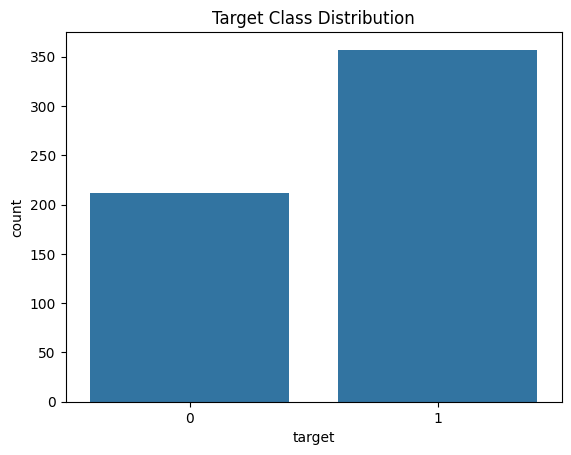


Features shape: (569, 30)
Target shape: (569,)
Target classes: ['malignant' 'benign']

Best Parameters: {'classifier__n_neighbors': 7}
Best CV Accuracy: 0.9714

Test Accuracy: 0.9737
Precision: 0.96
Recall: 1.0
F1-Score: 0.9796

Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



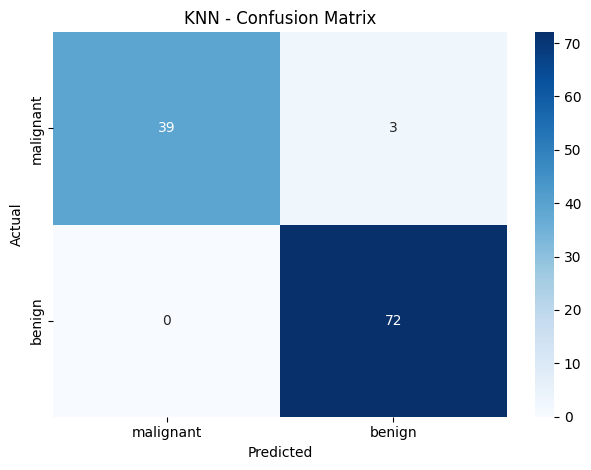

In [1]:

# Q33: End-to-End Machine Learning Pipeline using KNN

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Step 1: Load dataset
cancer = load_breast_cancer(as_frame=True)
df = cancer.frame

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nDataset information:")
df.info()

# Step 2: EDA
print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
print(df.describe())

print("\nTarget distribution:")
print(df["target"].value_counts())

sns.countplot(x="target", data=df)
plt.title("Target Class Distribution")
plt.show()

# Step 3: Separate features and target
X = df.drop(columns="target")
y = df["target"]

print("\nFeatures shape:", X.shape)
print("Target shape:", y.shape)
print("Target classes:", cancer.target_names)

# Step 4: Split data without leakage
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Step 5: Create KNN pipeline
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier())
])

# Step 6: Tune hyperparameter using 5-fold CV
params = {
    "classifier__n_neighbors": [3, 5, 7, 9, 11, 13, 15]
}
#Grid: The set of parameter combinations to try. Search: Tests those combinations. CV: Cross-validation, used to evaluate each combination.

grid = GridSearchCV(
    pipeline,
    params,
    cv=5,   #The training data is divided into five folds. Each time, four folds are used for training and one for validation.
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("\nBest Parameters:", grid.best_params_)
print("Best CV Accuracy:", round(grid.best_score_, 4))

# Step 7: Evaluate final model on test data
best_model = grid.best_estimator_   #returns best fitted model
y_pred = best_model.predict(X_test)

print("\nTest Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred), 4))
print("Recall:", round(recall_score(y_test, y_pred), 4))
print("F1-Score:", round(f1_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=cancer.target_names,
    yticklabels=cancer.target_names
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()
